# EM noise sweep: points per cluster, by manifold

One-off analysis of **all runs inside `*/models/*_em_bk/`** under
`dalg-cache/toy_manifolds_10types_1each_D128_30Keach_noise_sweep_seed0`.

A component is a cluster. We count its points from the **saved hard assignments**,
then associate its centroid with the **unique nearest noiseless manifold**, using
exactly the evaluator's helper and saved distance cutoff. No assignments or models
are recomputed. These bundles cover **training + validation**, not the independent
test set.

For each run and manifold, the numerator is the total points assigned to clusters
geometrically associated with that manifold. We report both:

- **All clusters:** total assigned points / associated clusters, including empty clusters.
- **Nonempty clusters:** total assigned points / associated clusters with at least one point.

The first is the default plotted average. A zero denominator gives NaN. All points
in a cluster count, even if their planted manifold differs from the centroid's
associated manifold. Ambiguous/outside-cutoff clusters remain explicitly
unassociated; they are retained in the cluster table and audit but excluded from
manifold means. PCA validity does not restrict this occupancy analysis.

The notebook retains `clusters_df` (one row per cluster), `summary_df` (one row per
run and manifold), and `audit_df` (one row per run), and exports them under
`outputs/experiments/toy_manifold_em_cluster_sizes/`.

In [1]:
from pathlib import Path
import json
import os
import sys
import time
from concurrent.futures import ProcessPoolExecutor, as_completed
from multiprocessing import get_context

import numpy as np
import pandas as pd
import torch
from IPython.display import display

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "src"))

from dalg.data.subset_spec import split_shard_dir_spec
from dalg.evaluation.toy_manifold_tiling import _load_model
from dalg.evaluation.toy_manifold_metrics import _associate_component_means

torch.set_num_threads(1)
DATA_DIR = REPO_ROOT / "dalg-cache/toy_manifolds_10types_1each_D128_30Keach_noise_sweep_seed0"
OUTPUT_DIR = REPO_ROOT / "outputs/experiments/toy_manifold_em_cluster_sizes"
# Linux cluster notebook: fork lets workers use the function defined in the next cell.
WORKERS = min(8, len(os.sched_getaffinity(0)))
NOISE_ORDER = ["noiseless", "1000", "100", "10"]

columns = ["source_path", "run_id", "K", "q_capacity", "surgery_threshold",
           "config.dataset.id", "config.training.arguments.fit_method"]
runs = pd.read_csv(DATA_DIR / "general_metrics.csv", usecols=columns)
runs = runs.loc[runs["source_path"].map(
    lambda value: any(part.endswith("_em_bk") for part in Path(value).parts[:-1])
)].copy()
runs["noise_ratio"] = runs["config.dataset.id"].str.extract(r"_noise(\d+)$", expand=False).fillna("noiseless")
runs = runs.sort_values(["noise_ratio", "K", "surgery_threshold"]).reset_index(drop=True)
assert len(runs) and runs["run_id"].is_unique
assert runs["config.training.arguments.fit_method"].eq("em").all()
assert not runs.duplicated(["noise_ratio", "K", "surgery_threshold"]).any()

# Check that the CSV includes every run with saved assignments in these directories.
assignment_paths = set(DATA_DIR.glob("*/models/*_em_bk/*/mfa_model_assignments.pt"))
selected_paths = { (DATA_DIR / p).parent / "mfa_model_assignments.pt" for p in runs["source_path"] }
assert selected_paths == assignment_paths, "CSV and EM assignment directories disagree."
print(f"Selected {len(runs)} EM runs; {WORKERS} CPU workers. Each run uses its saved assignments.")
display(runs.groupby(["noise_ratio", "K"]).size().unstack("K").reindex(NOISE_ORDER).rename_axis(columns="K (entries = thresholds)"))

Selected 180 EM runs; 8 CPU workers. Each run uses its saved assignments.


K (entries = thresholds),100,250,500,1000,2000
noise_ratio,,,,,
noiseless,9,9,9,9,9
1000,9,9,9,9,9
100,9,9,9,9,9
10,9,9,9,9,9


In [2]:
def analyze_run(row):
    torch.set_num_threads(1)
    metrics_path = DATA_DIR / row["source_path"]
    run_dir = metrics_path.parent
    metrics = json.loads(metrics_path.read_text())
    shard_path, subset_spec = split_shard_dir_spec(metrics["dataset"]["shard_dir"])
    shard_dir = Path(shard_path)
    assert subset_spec is None and metrics["dataset"]["subset_spec"] is None
    shard_config = json.loads((shard_dir / "config.json").read_text())
    assert shard_config["window"] == 1 and shard_config.get("drop_prefix", 0) == 0
    metadata = torch.load(shard_dir / shard_config["manifold_metadata"],
                          map_location="cpu", weights_only=True)

    assignment_path = run_dir / "mfa_model_assignments.pt"
    bundle = torch.load(assignment_path, map_location="cpu", weights_only=True, mmap=True)
    ids = bundle["assignments"].reshape(-1)
    sizes = bundle["cluster_sizes"].reshape(-1)
    assert ids.dtype in (torch.int32, torch.int64)
    assert sizes.dtype in (torch.int32, torch.int64)
    ids, sizes = ids.long(), sizes.long()
    K = int(row["K"])
    assert int(bundle["K"]) == K and sizes.numel() == K
    assert ids.numel() == metrics["dataset"]["selected_rows"] == metadata["row_manifold_ids"].numel()
    assert ids.numel() > 0 and int(ids.min()) >= 0 and int(ids.max()) < K
    assert bundle.get("subset_spec") is None
    assert torch.equal(torch.bincount(ids, minlength=K), sizes)
    assert int(sizes.sum()) == ids.numel()
    # Some historical MFA bundles predate the provenance fields.
    if "source" in bundle:
        assert Path(bundle["source"]["shard_dir"]).resolve() == shard_dir.resolve()
        assert bundle["source"]["num_items"] == ids.numel()
        assert bundle["source"]["layer"] == metrics["dataset"]["layer"]
        assert bundle["source"]["drop_prefix"] == 0
    if "model_path" in bundle:
        assert Path(bundle["model_path"]).resolve() == (run_dir / "mfa_model.pt").resolve()

    model = _load_model(run_dir, "hddc")  # EM uses the HDDC checkpoint format.
    assert model.K == K and model.D == shard_config["d_model"]
    associations = _associate_component_means(
        model.mu, metadata,
        max_mean_to_manifold_distance=metrics["association"]["max_mean_to_manifold_distance"],
    )
    manifold_indices = associations.manifold_indices.numpy()
    associated = manifold_indices >= 0
    manifold_ids = np.full(K, -1, dtype=np.int64)
    manifold_names = np.full(K, "unassociated", dtype=object)
    for index, manifold in enumerate(metadata["manifolds"]):
        mask = manifold_indices == index
        manifold_ids[mask] = manifold["manifold_id"]
        manifold_names[mask] = manifold["type_name"]
    common = {key: row[key] for key in ["run_id", "noise_ratio", "K", "q_capacity", "surgery_threshold"]}
    cluster_table = pd.DataFrame({
        "cluster_id": np.arange(K), "manifold_id": manifold_ids,
        "type_name": manifold_names, "n_points": sizes.numpy(),
        "nearest_manifold_distance": associations.nearest_distances.numpy(),
        "association_status": np.where(associated, "associated",
            np.where(associations.ambiguous.numpy(), "ambiguous", "outside_cutoff")),
    }).assign(**common)

    expected = {entry["manifold_id"]: entry["components"] for entry in metrics["per_manifold"]}
    summary_rows = []
    for manifold in metadata["manifolds"]:
        counts = cluster_table.loc[cluster_table["manifold_id"].eq(manifold["manifold_id"]), "n_points"]
        n_clusters = len(counts)
        n_live = int(counts.gt(0).sum())
        n_points = int(counts.sum())
        assert n_clusters == expected[manifold["manifold_id"]]["associated"]
        assert n_live == expected[manifold["manifold_id"]]["assignment_live"]
        summary_rows.append({
            **common,
            **{key: manifold[key] for key in ["manifold_id", "type_name", "intrinsic_dim", "embedding_dim"]},
            "associated_clusters": n_clusters, "nonempty_clusters": n_live,
            "empty_clusters": n_clusters - n_live, "assigned_points": n_points,
            "avg_points_all_clusters": n_points / n_clusters if n_clusters else np.nan,
            "avg_points_nonempty_clusters": n_points / n_live if n_live else np.nan,
        })
    audit = {
        **common, "source_path": row["source_path"],
        "assignment_path": str(assignment_path.relative_to(DATA_DIR)),
        "assignment_points": ids.numel(), "associated_clusters": int(associated.sum()),
        "unassociated_clusters": int((~associated).sum()),
        "unassociated_points": int(sizes[torch.from_numpy(~associated)].sum()),
    }
    assert audit["associated_clusters"] == metrics["association"]["associated_components"]
    assert int(associations.ambiguous.sum()) == metrics["association"]["ambiguous_components"]
    assert int(associations.outside_cutoff.sum()) == metrics["association"]["outside_cutoff_components"]
    assert sum(entry["assigned_points"] for entry in summary_rows) + audit["unassociated_points"] == ids.numel()
    return cluster_table, summary_rows, audit

In [3]:
started = time.monotonic()
cluster_tables, summary_rows, audit_rows = [], [], []
with ProcessPoolExecutor(max_workers=WORKERS, mp_context=get_context("fork")) as pool:
    futures = {pool.submit(analyze_run, row): row["run_id"] for row in runs.to_dict("records")}
    for completed, future in enumerate(as_completed(futures), 1):
        cluster_table, run_summary, audit = future.result()
        cluster_tables.append(cluster_table)
        summary_rows.extend(run_summary)
        audit_rows.append(audit)
        if completed == 1 or completed % 10 == 0 or completed == len(runs):
            print(f"{completed}/{len(runs)} runs complete ({time.monotonic() - started:.0f} s)", flush=True)

clusters_df = pd.concat(cluster_tables, ignore_index=True).sort_values(["run_id", "cluster_id"]).reset_index(drop=True)
summary_df = pd.DataFrame(summary_rows).sort_values(["noise_ratio", "K", "surgery_threshold", "manifold_id"]).reset_index(drop=True)
audit_df = pd.DataFrame(audit_rows).sort_values("run_id").reset_index(drop=True)
assert len(clusters_df) == runs["K"].sum()
assert len(summary_df) == len(runs) * 10
assert audit_df["assignment_points"].eq(300000).all()
assert not clusters_df.duplicated(["run_id", "cluster_id"]).any()
assert not summary_df.duplicated(["run_id", "manifold_id"]).any()
print(f"Validated {len(clusters_df):,} clusters and {len(summary_df):,} manifold/run summaries.")
print(f"Unassociated clusters: {audit_df.unassociated_clusters.sum():,}; their points: {audit_df.unassociated_points.sum():,}")
display(clusters_df.head(10))

1/180 runs complete (1 s)
10/180 runs complete (2 s)
20/180 runs complete (5 s)
30/180 runs complete (12 s)
40/180 runs complete (25 s)
50/180 runs complete (26 s)
60/180 runs complete (29 s)
70/180 runs complete (34 s)


80/180 runs complete (43 s)
90/180 runs complete (52 s)
100/180 runs complete (55 s)
110/180 runs complete (59 s)
120/180 runs complete (65 s)
130/180 runs complete (78 s)
140/180 runs complete (81 s)
150/180 runs complete (83 s)
160/180 runs complete (88 s)
170/180 runs complete (96 s)
180/180 runs complete (117 s)
Validated 138,600 clusters and 1,800 manifold/run summaries.
Unassociated clusters: 0; their points: 0


,cluster_id,manifold_id,type_name,n_points,nearest_manifold_distance,association_status,run_id,noise_ratio,K,q_capacity,surgery_threshold
0,0,1,circle,1167,0.002506,associated,hddc__toy_manifolds_10types_1each_d128_30keach...,1000,1000,32,0.15
1,1,2,sphere,451,0.018285,associated,hddc__toy_manifolds_10types_1each_d128_30keach...,1000,1000,32,0.15
2,2,4,swiss_roll,0,0.009179,associated,hddc__toy_manifolds_10types_1each_d128_30keach...,1000,1000,32,0.15
3,3,0,segment,2832,0.000211,associated,hddc__toy_manifolds_10types_1each_d128_30keach...,1000,1000,32,0.15
4,4,9,cylinder,539,0.008733,associated,hddc__toy_manifolds_10types_1each_d128_30keach...,1000,1000,32,0.15
5,5,7,hypersphere_10d,0,0.010799,associated,hddc__toy_manifolds_10types_1each_d128_30keach...,1000,1000,32,0.15
6,6,3,torus,834,0.002969,associated,hddc__toy_manifolds_10types_1each_d128_30keach...,1000,1000,32,0.15
7,7,9,cylinder,716,0.011926,associated,hddc__toy_manifolds_10types_1each_d128_30keach...,1000,1000,32,0.15
8,8,6,helix_4d,1060,0.006453,associated,hddc__toy_manifolds_10types_1each_d128_30keach...,1000,1000,32,0.15
9,9,5,helix,964,0.005433,associated,hddc__toy_manifolds_10types_1each_d128_30keach...,1000,1000,32,0.15


## Save the complete results

The summary CSV contains both averages for every EM configuration. The compressed
cluster CSV retains the complete cluster-to-manifold mapping and exact occupancy.
Use `pd.read_csv(...)` to reload any of these without recomputing associations.

In [4]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(OUTPUT_DIR / "points_per_cluster_by_manifold.csv", index=False)
clusters_df.to_csv(OUTPUT_DIR / "cluster_manifold_mapping.csv.gz", index=False, compression="gzip")
audit_df.to_csv(OUTPUT_DIR / "run_audit.csv", index=False)
print(OUTPUT_DIR)
display(summary_df.head(10))

/orfeo/cephfs/home/dssc/zenocosini/decomposing-activations-local-geometry/outputs/experiments/toy_manifold_em_cluster_sizes


,run_id,noise_ratio,K,q_capacity,surgery_threshold,manifold_id,type_name,intrinsic_dim,embedding_dim,associated_clusters,nonempty_clusters,empty_clusters,assigned_points,avg_points_all_clusters,avg_points_nonempty_clusters
0,hddc__toy_manifolds_10types_1each_d128_30keach...,10,100,32,0.00025,0,segment,1,1,10,10,0,30000,3000.000000,3000.000000
1,hddc__toy_manifolds_10types_1each_d128_30keach...,10,100,32,0.00025,1,circle,1,2,11,11,0,30000,2727.272727,2727.272727
2,hddc__toy_manifolds_10types_1each_d128_30keach...,10,100,32,0.00025,2,sphere,2,3,12,12,0,30000,2500.000000,2500.000000
3,hddc__toy_manifolds_10types_1each_d128_30keach...,10,100,32,0.00025,3,torus,2,3,6,6,0,30000,5000.000000,5000.000000
4,hddc__toy_manifolds_10types_1each_d128_30keach...,10,100,32,0.00025,4,swiss_roll,2,3,10,10,0,30000,3000.000000,3000.000000
5,hddc__toy_manifolds_10types_1each_d128_30keach...,10,100,32,0.00025,5,helix,1,3,13,13,0,30000,2307.692308,2307.692308
6,hddc__toy_manifolds_10types_1each_d128_30keach...,10,100,32,0.00025,6,helix_4d,1,4,9,9,0,30000,3333.333333,3333.333333
7,hddc__toy_manifolds_10types_1each_d128_30keach...,10,100,32,0.00025,7,hypersphere_10d,10,11,16,16,0,30000,1875.000000,1875.000000
8,hddc__toy_manifolds_10types_1each_d128_30keach...,10,100,32,0.00025,8,product_torus_12d,12,24,4,4,0,30000,7500.000000,7500.000000
9,hddc__toy_manifolds_10types_1each_d128_30keach...,10,100,32,0.00025,9,cylinder,2,3,9,9,0,30000,3333.333333,3333.333333


## Compare noise conditions at one K and threshold

Change these two selections to inspect another configuration. Both tables use
exact saved occupancies. Rows are ordered by intrinsic dimension, then embedding
dimension.

In [5]:
DISPLAY_K = 2000
DISPLAY_THRESHOLD = 0.05
manifold_info = (summary_df[["manifold_id", "type_name", "intrinsic_dim", "embedding_dim"]]
                 .drop_duplicates().sort_values(["intrinsic_dim", "embedding_dim", "manifold_id"]))
selected = summary_df.loc[summary_df["K"].eq(DISPLAY_K)
                          & summary_df["surgery_threshold"].eq(DISPLAY_THRESHOLD)]
assert not selected.empty
for metric, title in [
    ("avg_points_all_clusters", "Average points per cluster — including empty clusters"),
    ("avg_points_nonempty_clusters", "Average points per nonempty cluster"),
]:
    table = selected.pivot(index="type_name", columns="noise_ratio", values=metric)
    table = table.reindex(index=manifold_info["type_name"], columns=NOISE_ORDER)
    display(table.style.format("{:.1f}", na_rep="—").set_caption(
        f"{title}; K={DISPLAY_K}, threshold={DISPLAY_THRESHOLD}"))

noise_ratio,noiseless,1000,100,10
type_name,,,,
segment,1666.7,1764.7,731.7,127.7
circle,1200.0,1200.0,697.7,106.8
helix,769.2,789.5,612.2,149.3
helix_4d,789.5,789.5,600.0,144.9
sphere,322.6,322.6,260.9,108.7
torus,344.8,340.9,344.8,337.1
swiss_roll,245.9,247.9,254.2,428.6
cylinder,319.1,315.8,306.1,288.5
hypersphere_10d,55.8,55.4,57.1,82.4


noise_ratio,noiseless,1000,100,10
type_name,,,,
segment,1666.7,1764.7,731.7,127.7
circle,1200.0,1200.0,697.7,106.8
helix,769.2,789.5,612.2,149.3
helix_4d,789.5,789.5,600.0,144.9
sphere,322.6,322.6,260.9,108.7
torus,344.8,340.9,344.8,337.1
swiss_roll,245.9,247.9,254.2,428.6
cylinder,319.1,315.8,306.1,288.5
hypersphere_10d,180.7,182.9,60.4,82.4


## Full K × threshold sweep for each manifold

One figure per noise condition; each panel is one manifold. Values are points per
cluster. Switch `PLOT_METRIC` to `avg_points_nonempty_clusters` to exclude empty
clusters. All panels use a common color scale; blank cells have no contributing
clusters.

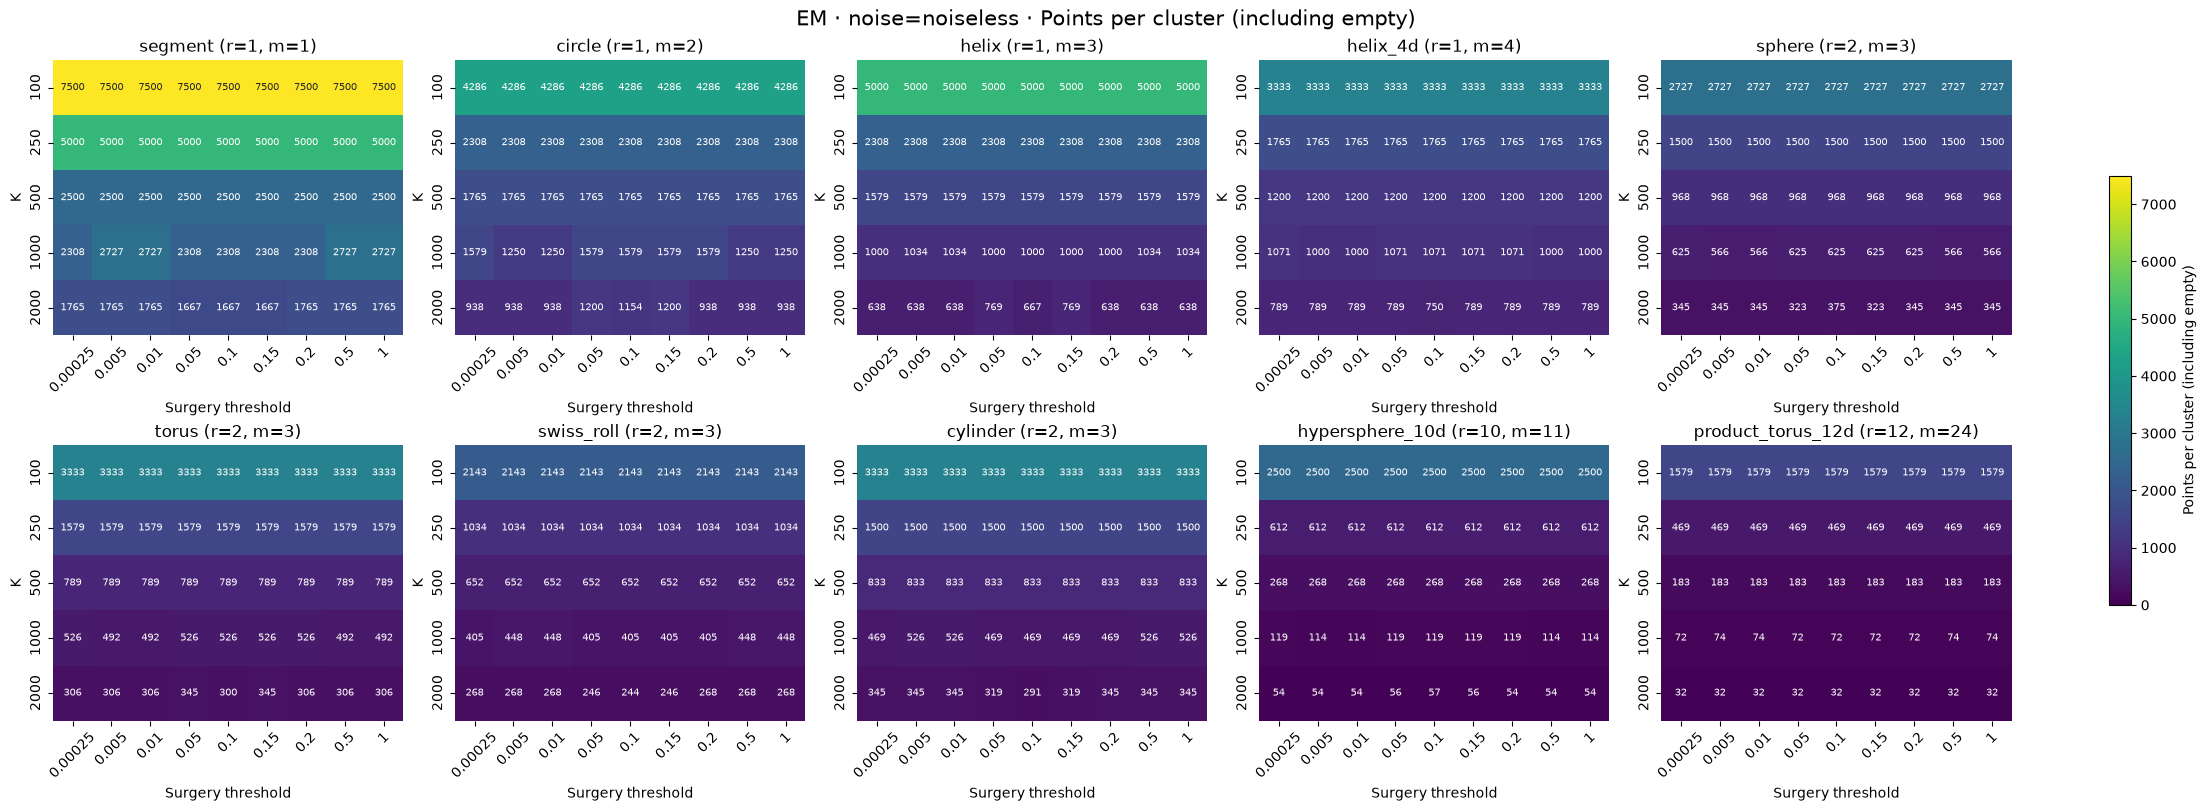

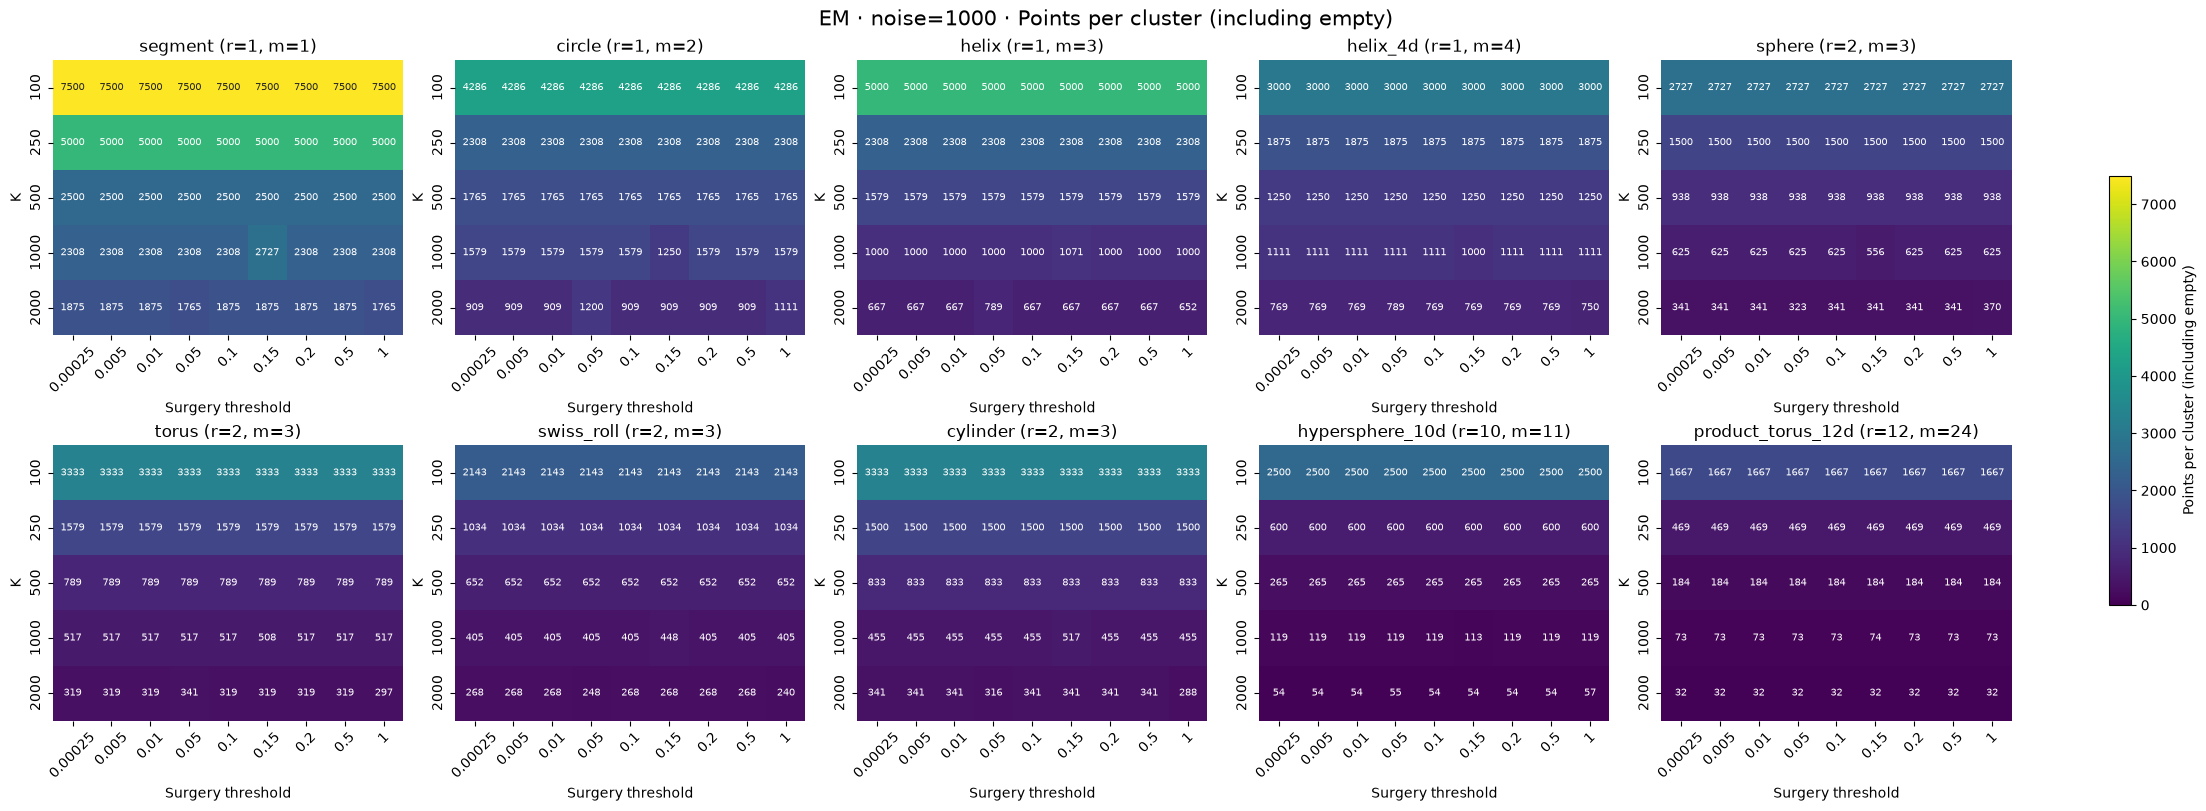

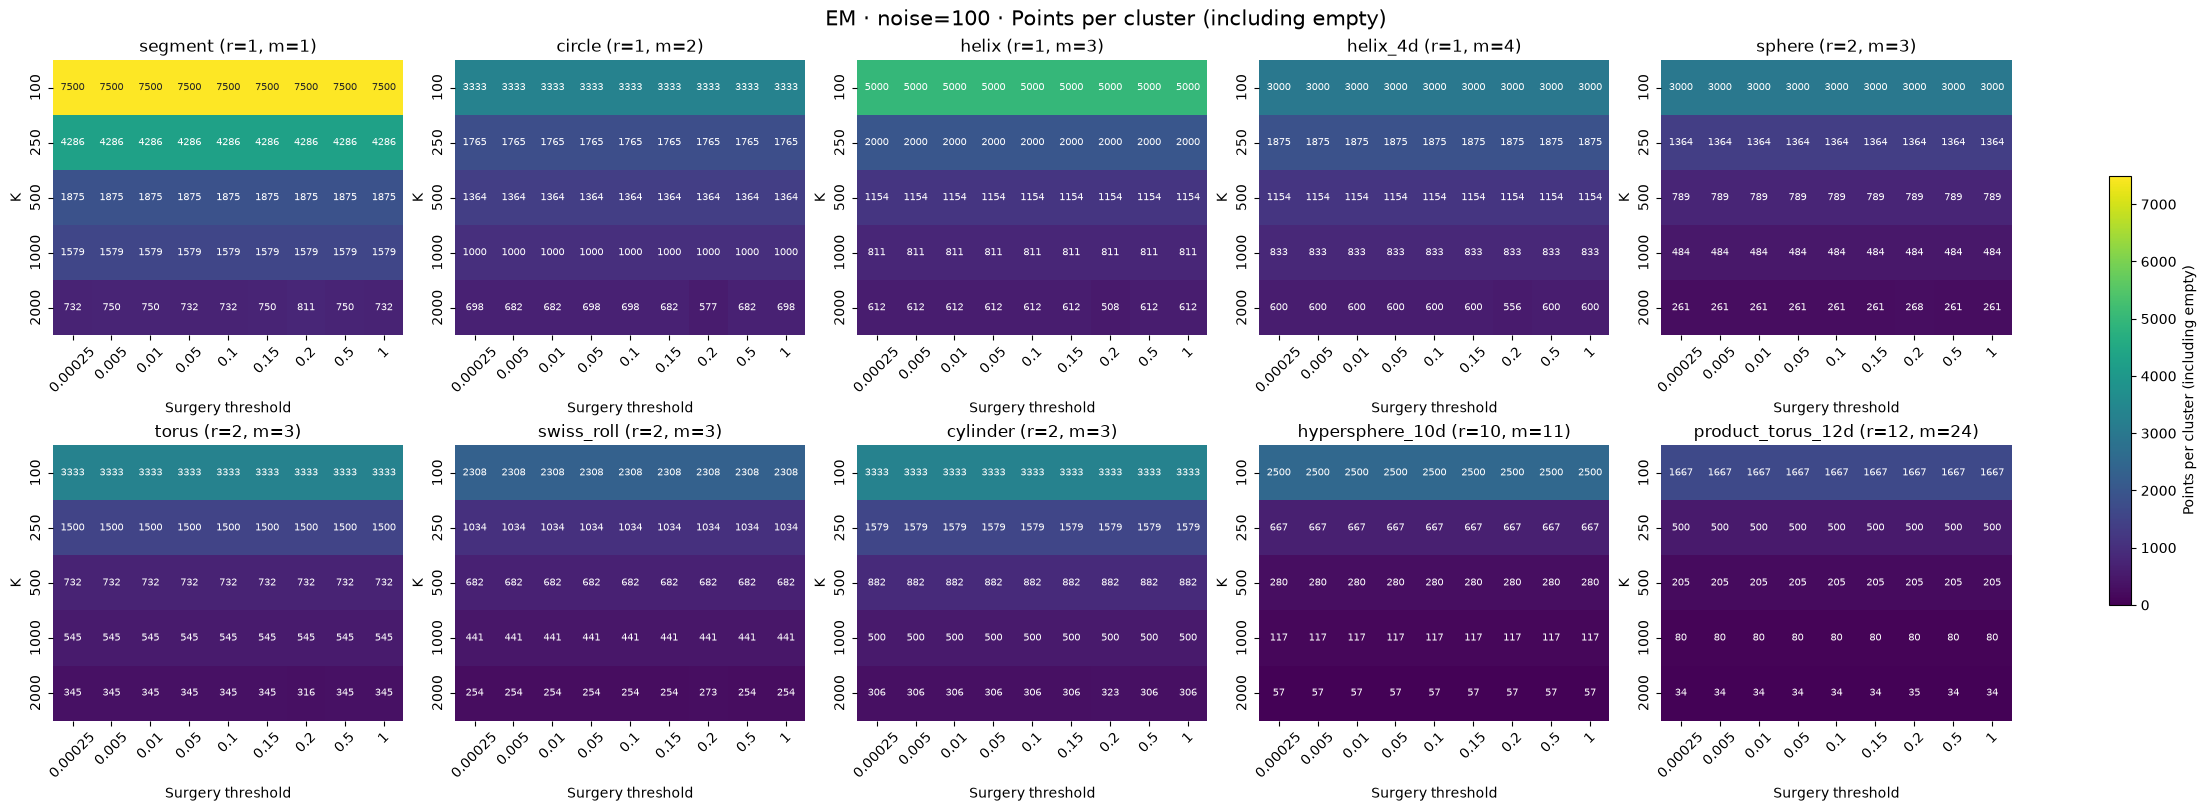

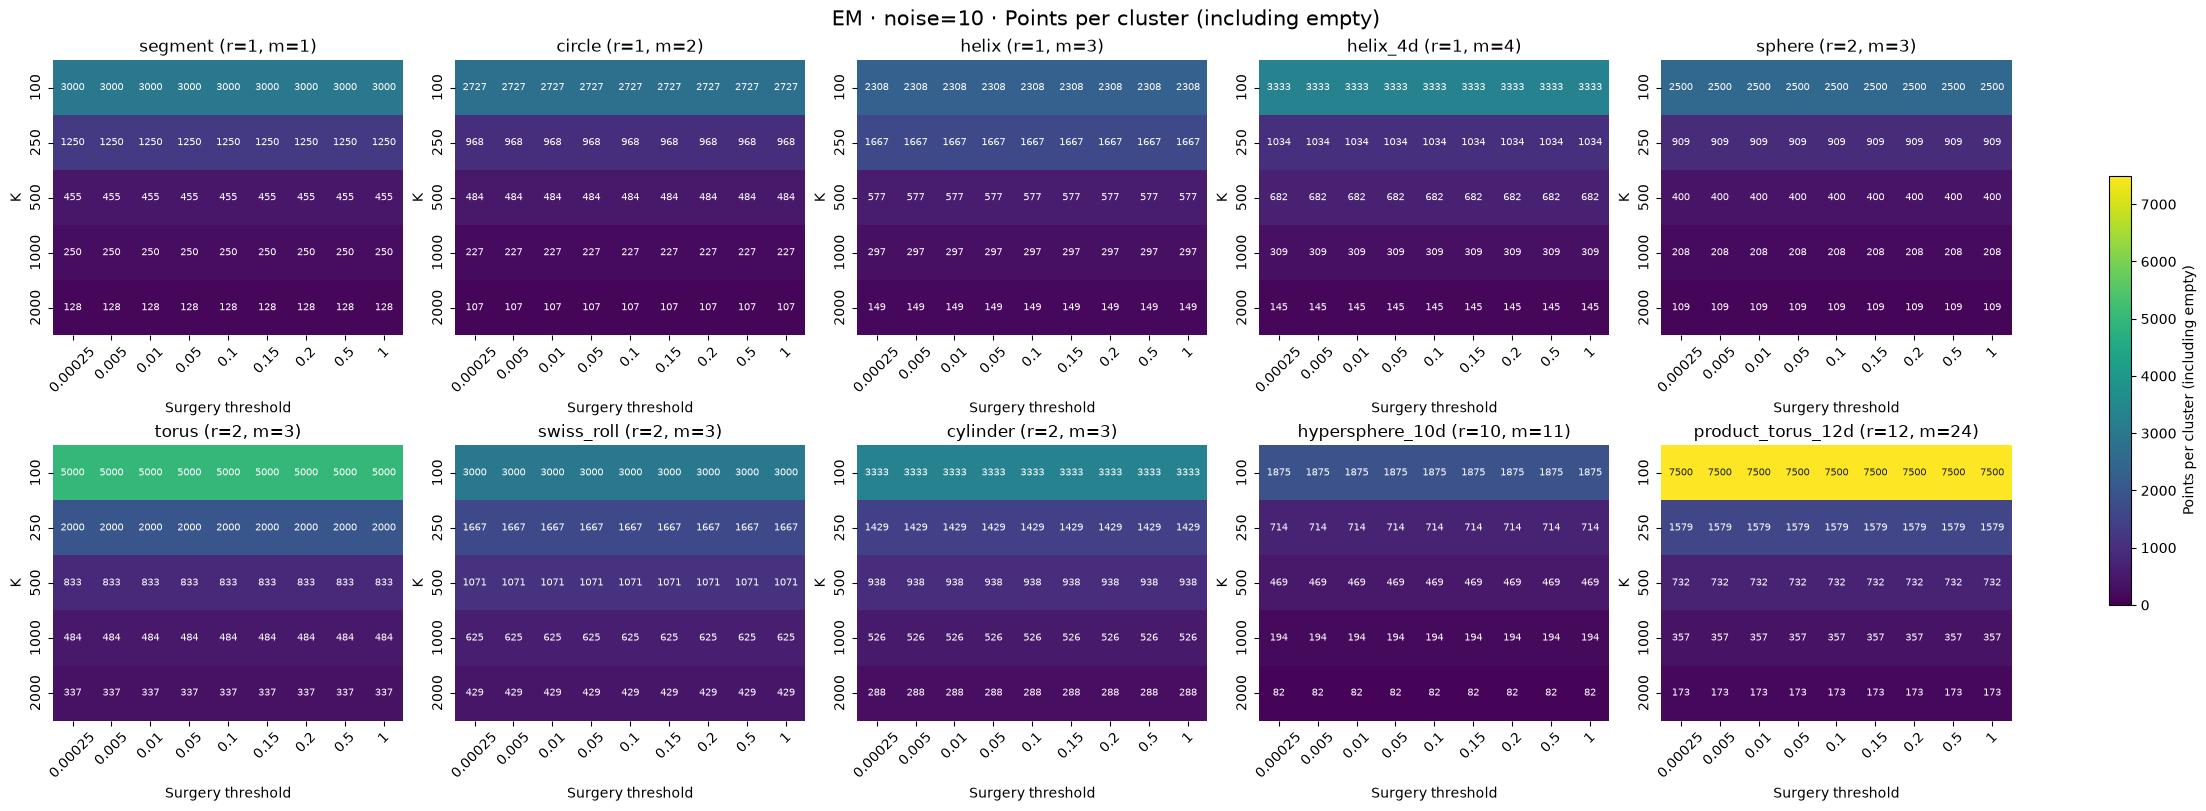

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

PLOT_METRIC = "avg_points_all_clusters"
assert PLOT_METRIC in ["avg_points_all_clusters", "avg_points_nonempty_clusters"]
metric_title = {"avg_points_all_clusters": "Points per cluster (including empty)",
                "avg_points_nonempty_clusters": "Points per nonempty cluster"}[PLOT_METRIC]
k_values = sorted(summary_df["K"].unique())
thresholds = sorted(summary_df["surgery_threshold"].unique())
vmax = summary_df[PLOT_METRIC].max()
for noise in NOISE_ORDER:
    fig, axes = plt.subplots(2, 5, figsize=(22, 8), layout="constrained")
    for ax, manifold in zip(axes.flat, manifold_info.to_dict("records")):
        subset = summary_df.loc[summary_df["noise_ratio"].eq(noise)
                                & summary_df["manifold_id"].eq(manifold["manifold_id"])]
        table = subset.pivot(index="K", columns="surgery_threshold", values=PLOT_METRIC)
        table = table.reindex(index=k_values, columns=thresholds)
        sns.heatmap(table, ax=ax, cmap="viridis", vmin=0, vmax=vmax,
                    annot=True, fmt=".0f", annot_kws={"fontsize": 7}, cbar=False,
                    xticklabels=[f"{t:g}" for t in thresholds], yticklabels=k_values)
        ax.set_title(f"{manifold['type_name']} (r={manifold['intrinsic_dim']}, m={manifold['embedding_dim']})")
        ax.set_xlabel("Surgery threshold")
        ax.set_ylabel("K")
        ax.tick_params(axis="x", rotation=45)
    fig.colorbar(axes.flat[0].collections[0], ax=list(axes.flat), shrink=0.65, label=metric_title)
    fig.suptitle(f"EM · noise={noise} · {metric_title}", fontsize=15)
    plt.show()